# E02 — Correlación: baskets, worst-of y quantos

**Objetivos:** simular activos correlacionados con Cholesky; valorar baskets, *best-of* y *worst-of* y medir su
sensibilidad a la correlación; valorar un quanto y su ajuste de drift; calcular la correlación implícita y el P&L
de una operación de dispersión; explicar a un cliente por qué un worst-of sobre tres bancos paga mucho más cupón
que el mismo producto sobre el índice.

**Fuentes:** Hull cap. 26 (26.14 y 26.15) y cap. 30 (30.3, quantos); Schofield, *Equity Derivatives*, cap. 8 y 15
(15.4.5, dispersión). Datos sintéticos: tres bancos europeos ficticios, volatilidades planas.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent          # notebooks/ -> repository root
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True

from scipy.stats import norm
from derivlab.market import sample_market
from derivlab.curves import build_curves, discount_t
from derivlab.equity import bs_price, flat_curve
from derivlab.multi_asset import (BANKS, BANK_VOLS, BANK_DIV_YIELDS, BANK_CORR, INDEX_VOL_FLAT, INDEX_DIV_YIELD,
                                  cholesky_paths, corr_sqrt, basket_vol, implied_correlation, flat_corr,
                                  quanto_forward, quanto_drift_adjustment)
from derivlab.structured import funding_dfs, solve_coupon

estr, eur = build_curves(sample_market())
print(pd.DataFrame({"vol": BANK_VOLS, "dividend yield": BANK_DIV_YIELDS}, index=BANKS))
print(pd.DataFrame(BANK_CORR, index=BANKS, columns=BANKS))

                   vol  dividend yield
Banco Cantabrico  0.30           0.060
Banca Lombarda    0.32           0.050
Banque du Rhin    0.28           0.055
                  Banco Cantabrico  Banca Lombarda  Banque du Rhin
Banco Cantabrico              1.00            0.75            0.70
Banca Lombarda                0.75            1.00            0.65
Banque du Rhin                0.70            0.65            1.00


## 1. Simulación correlacionada: Cholesky

Si $Z$ son normales independientes y $\Sigma = LL^\top$ la matriz de correlación, $W = LZ$ tiene correlación
$\Sigma$. Cada activo sigue $\ln S_i(t+\delta t) = \ln S_i(t) + (r - q_i - \tfrac12\sigma_i^2)\delta t +
\sigma_i\sqrt{\delta t}\,W_i$. Si la matriz no es definida positiva (por ejemplo, correlación 1), se usa la raíz
por autovalores.

In [2]:
L = corr_sqrt(BANK_CORR)
print("Cholesky factor L:")
print(np.round(L, 4))
paths = cholesky_paths(np.full(3, 100.0), BANK_VOLS, BANK_DIV_YIELDS, BANK_CORR, [1.0, 2.0], 200000, estr, seed=3)
lr = np.log(paths[:, :, 1] / 100.0)
sample = np.corrcoef(lr.T)
print("Sample correlation of 1y log returns:")
print(np.round(sample, 3))
P2 = discount_t(estr, 2.0)
print("2y mean vs forward:", np.round(paths[:, :, -1].mean(axis=0), 2), np.round(100 * np.exp(-2 * BANK_DIV_YIELDS) / P2, 2))
print(f"CASE largest error in the simulated correlation: {np.abs(sample - BANK_CORR).max():.4f}")

Cholesky factor L:
[[1.     0.     0.    ]
 [0.75   0.6614 0.    ]
 [0.7    0.189  0.6887]]
Sample correlation of 1y log returns:
[[1.    0.75  0.698]
 [0.75  1.    0.647]
 [0.698 0.647 1.   ]]
2y mean vs forward: [92.23 94.12 93.21] [92.25 94.11 93.18]
CASE largest error in the simulated correlation: 0.0030


## 2. Baskets, best-of y worst-of: ¿largo o corto correlación?

La volatilidad de un basket con pesos $w_i$ es $\sigma_B^2 \approx \sum_{i,j} w_i w_j \sigma_i \sigma_j \rho_{ij}$: baja
al bajar la correlación (diversificación). Para opciones sobre el peor o el mejor de varios activos el efecto se
invierte según el pago (Schofield 8.3):

| Opción | Al subir la correlación | Quien la compra es |
| --- | --- | --- |
| Call sobre basket | sube | largo correlación |
| Call *best-of* | baja | corto correlación |
| Put *worst-of* | baja | corto correlación |
| Call *worst-of* | sube | largo correlación |

Se valoran a un año, strike 100 %, con correlación uniforme entre los tres bancos.

 correlation  basket call  best-of call  worst-of call  worst-of put  basket vol
         0.0        5.129        23.889          0.543        26.772       0.173
         0.3        6.780        21.377          1.462        24.208       0.219
         0.5        7.727        19.457          2.408        22.328       0.245
         0.7        8.592        17.157          3.773        20.154       0.268
         0.9        9.398        13.986          6.060        17.200       0.290
         1.0        9.859        10.863          9.075        13.936       0.300


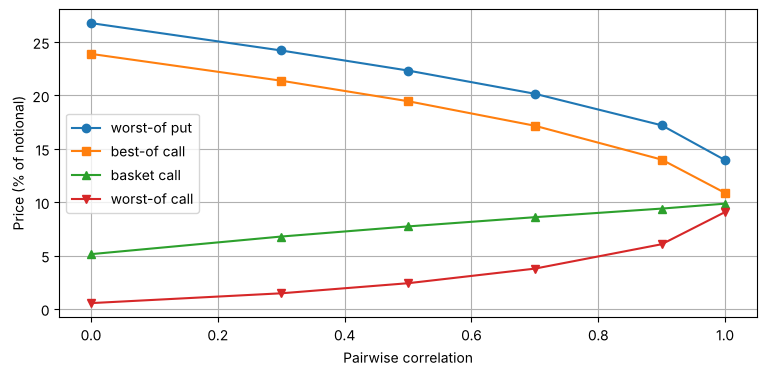

CASE 1y worst-of put: 26.77% at correlation 0, 20.15% at 0.7, 13.94% at 1


In [3]:
P1 = discount_t(estr, 1.0)
rows = []
for rho in [0.0, 0.3, 0.5, 0.7, 0.9, 1.0]:
    p = cholesky_paths(np.full(3, 100.0), BANK_VOLS, BANK_DIV_YIELDS, flat_corr(3, rho), [1.0], 200000, estr, seed=7)[:, :, -1]
    basket = p.mean(axis=1)
    rows.append({"correlation": rho,
                 "basket call": P1 * np.maximum(basket - 100, 0).mean(),
                 "best-of call": P1 * np.maximum(p.max(axis=1) - 100, 0).mean(),
                 "worst-of call": P1 * np.maximum(p.min(axis=1) - 100, 0).mean(),
                 "worst-of put": P1 * np.maximum(100 - p.min(axis=1), 0).mean(),
                 "basket vol": basket_vol([1 / 3] * 3, BANK_VOLS, flat_corr(3, rho))})
corr_tab = pd.DataFrame(rows)
print(corr_tab.round(3).to_string(index=False))
plt.plot(corr_tab.correlation, corr_tab["worst-of put"], "o-", label="worst-of put")
plt.plot(corr_tab.correlation, corr_tab["best-of call"], "s-", label="best-of call")
plt.plot(corr_tab.correlation, corr_tab["basket call"], "^-", label="basket call")
plt.plot(corr_tab.correlation, corr_tab["worst-of call"], "v-", label="worst-of call")
plt.xlabel("Pairwise correlation"); plt.ylabel("Price (% of notional)"); plt.legend(); plt.show()
print(f"CASE 1y worst-of put: {corr_tab['worst-of put'].iloc[0]:.2f}% at correlation 0, {corr_tab['worst-of put'].iloc[3]:.2f}% at 0.7, "
      f"{corr_tab['worst-of put'].iloc[-1]:.2f}% at 1")

**Lectura.** Con correlación 1 los tres bancos se mueven a la vez y el *worst-of* es casi una opción sobre el banco
más volátil. Con correlación 0 basta con que uno de los tres caiga, y la put *worst-of* vale casi el doble. Quien
vende una put *worst-of* (el inversor de un producto *worst-of*) es largo correlación: gana si los activos se
mueven juntos. El banco que la compra queda corto correlación, que es lo que deja el negocio de estructurados en
los libros de los bancos (Schofield 12.1).

## 3. Quantos: un índice extranjero pagado en euros sin riesgo de cambio

Un inversor en euros quiere una call sobre un índice estadounidense que pague 1 € por punto, sin exposición al
EURUSD. En la medida neutral al riesgo en euros, el índice tiene un drift
$r_{USD} - q - \rho\,\sigma_S\,\sigma_X$, con $X$ el precio en euros de un dólar y $\rho$ la correlación entre el
índice y $X$ (Hull 30.3). En las caídas de la bolsa estadounidense el dólar suele apreciarse (sube $X$): $\rho<0$ y
el forward quanto queda por encima del forward en dólares.

In [4]:
S_us, q_us, vol_us, r_usd, vol_fx, T = 6000.0, 0.013, 0.18, 0.038, 0.08, 1.0
F_usd = S_us * np.exp((r_usd - q_us) * T)
P_eur = discount_t(estr, T)
qrows = []
for rho in [-0.5, -0.3, 0.0, 0.3, 0.5]:
    Fq = quanto_forward(F_usd, T, rho, vol_us, vol_fx)
    qrows.append({"rho(S, EUR per USD)": rho, "drift adjustment": quanto_drift_adjustment(rho, vol_us, vol_fx),
                  "quanto forward": Fq, "ATM call, EUR per point": bs_price(Fq, S_us, T, vol_us, P_eur, True)})
qt = pd.DataFrame(qrows)
print(f"USD forward {F_usd:,.1f}")
print(qt.to_string(index=False, formatters={"drift adjustment": "{:+.3%}".format, "quanto forward": "{:,.1f}".format,
      "ATM call, EUR per point": "{:,.2f}".format}))
# Monte Carlo check under the EUR measure: Y = S X is a EUR asset, X drifts at r_EUR - r_USD
rho, n = -0.3, 400000
rng = np.random.default_rng(9)
z1 = rng.standard_normal(n); z2 = rho * z1 + np.sqrt(1 - rho ** 2) * rng.standard_normal(n)
r_eur = -np.log(P_eur) / T
vy = np.sqrt(vol_us ** 2 + vol_fx ** 2 + 2 * rho * vol_us * vol_fx)
Y = S_us * np.exp((r_eur - q_us - 0.5 * vy ** 2) * T + np.sqrt(T) * (vol_us * z1 + vol_fx * z2))
X = np.exp((r_eur - r_usd - 0.5 * vol_fx ** 2) * T + vol_fx * np.sqrt(T) * z2)
mc_fwd = (Y / X).mean()
print(f"CASE quanto forward with rho = -0.3: formula {quanto_forward(F_usd, T, rho, vol_us, vol_fx):,.1f}, Monte Carlo {mc_fwd:,.1f}")

USD forward 6,151.9
 rho(S, EUR per USD) drift adjustment quanto forward ATM call, EUR per point
                -0.5          +0.720%        6,196.3                  532.32
                -0.3          +0.432%        6,178.5                  521.77
                 0.0          -0.000%        6,151.9                  506.22
                 0.3          -0.432%        6,125.4                  490.97
                 0.5          -0.720%        6,107.8                  480.98
CASE quanto forward with rho = -0.3: formula 6,178.5, Monte Carlo 6,181.6


## 4. Correlación implícita y dispersión

Si un índice sectorial (los tres bancos a partes iguales) cotiza una volatilidad implícita $\sigma_I$ y cada banco
la suya, la correlación media que cuadra la varianza del índice es
$$\rho_{impl} = \frac{\sigma_I^2 - \sum_i w_i^2\sigma_i^2}{\sum_{i\neq j} w_i w_j \sigma_i \sigma_j}$$
Una **dispersión** vende varianza del índice y compra varianza de los componentes: si las volatilidades de cada
banco se realizan como sus implícitas, gana cuando la correlación realizada queda por debajo de la implícita
(Schofield 15.4.5). Los bancos, cortos correlación por sus estructurados, son compradores naturales de
correlación, y eso suele dejar la correlación implícita por encima de la realizada.

In [5]:
w = np.array([1 / 3] * 3)
sector_vol = 0.275
rho_impl = implied_correlation(sector_vol, w, BANK_VOLS)
N_vega = 100000.0                                  # EUR per vol point on the index leg
N_var = N_vega / (2 * sector_vol * 100)
disp = []
for rho_real in [0.40, 0.55, rho_impl, 0.85, 0.95]:
    realised_index_vol = basket_vol(w, BANK_VOLS, flat_corr(3, rho_real))
    pnl = N_var * ((sector_vol * 100) ** 2 - (realised_index_vol * 100) ** 2)
    disp.append({"realised correlation": rho_real, "realised index vol": realised_index_vol, "dispersion P&L (EUR)": pnl})
disp = pd.DataFrame(disp)
print(f"CASE sector implied vol {sector_vol:.1%} -> implied correlation {rho_impl:.3f}")
print(disp.to_string(index=False, formatters={"realised correlation": "{:.2f}".format, "realised index vol": "{:.2%}".format,
      "dispersion P&L (EUR)": "{:,.0f}".format}))

CASE sector implied vol 27.5% -> implied correlation 0.760
realised correlation realised index vol dispersion P&L (EUR)
                0.40             23.25%              392,212
                0.55             25.11%              228,818
                0.76             27.50%                    0
                0.85             28.46%              -97,970
                0.95             29.50%             -206,899


## 5. Caso: un *worst-of* sobre tres bancos frente al mismo producto sobre el índice

**Situación.** Una red de banca privada pide un producto a dos años con cupón anual fijo y capital en riesgo: si al
vencimiento el **peor** de los tres bancos está por debajo del 60 % de su nivel inicial, el cliente recibe la
rentabilidad de ese banco; si no, el 100 %. El emisor se financia a €STR + 0,80 % y quiere un margen del 2 %. La red
pregunta por qué el cupón es tan alto comparado con el mismo producto sobre el índice, y qué debe explicar al
cliente. Volatilidades planas, sin skew (el efecto del skew se ve en E3).

In [6]:
obs = np.array([1.0, 2.0])
dfs = funding_dfs(estr, obs, 0.008)

def note(perf_T, c, barrier=0.60):
    redemption = np.where(perf_T >= barrier, 1.0, perf_T)
    return c * dfs.sum() + (redemption * dfs[-1]).mean()

def fair(perf_T, barrier=0.60):
    return solve_coupon(lambda c: note(perf_T, c, barrier), 0.98, -0.05, 0.5)

def worst(corr=BANK_CORR, vols=BANK_VOLS, seed=3):
    p = cholesky_paths(np.full(3, 100.0), vols, BANK_DIV_YIELDS, corr, obs, 200000, estr, seed=seed)
    return p[:, :, -1].min(axis=1) / 100.0

index_T = cholesky_paths([100.0], [INDEX_VOL_FLAT], [INDEX_DIV_YIELD], [[1.0]], obs, 200000, estr, seed=3)[:, 0, -1] / 100
singles = [cholesky_paths([100.0], [BANK_VOLS[i]], [BANK_DIV_YIELDS[i]], [[1.0]], obs, 200000, estr, seed=3)[:, 0, -1] / 100
           for i in range(3)]
wo_T = worst()
products = {"index (vol 18%)": index_T, **{f"{BANKS[i]} alone": singles[i] for i in range(3)}, "worst-of the three banks": wo_T}
case = pd.DataFrame({k: {"fair coupon": fair(v), "P(capital loss)": (v < 0.60).mean(),
                         "average redemption if loss": v[v < 0.60].mean() if (v < 0.60).any() else np.nan}
                     for k, v in products.items()}).T
print(case.to_string(formatters={"fair coupon": "{:.2%}".format, "P(capital loss)": "{:.1%}".format,
      "average redemption if loss": "{:.0%}".format}))
c_wo, c_idx = case.loc["worst-of the three banks", "fair coupon"], case.loc["index (vol 18%)", "fair coupon"]
print(f"CASE coupon: index {c_idx:.2%}, worst-of {c_wo:.2%}; probability of losing capital {case['P(capital loss)'].iloc[0]:.1%} vs "
      f"{case['P(capital loss)'].iloc[-1]:.1%}")

                         fair coupon P(capital loss) average redemption if loss
index (vol 18%)                2.63%            3.8%                        54%
Banco Cantabrico alone         7.15%           21.1%                        48%
Banca Lombarda alone           7.49%           22.0%                        47%
Banque du Rhin alone           6.28%           18.0%                        49%
worst-of the three banks      10.85%           34.6%                        47%
CASE coupon: index 2.63%, worst-of 10.85%; probability of losing capital 3.8% vs 34.6%


In [7]:
sens = []
for rho in [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:
    c = flat_corr(3, rho)
    sens.append({"correlation": rho, "fair coupon": fair(worst(c))})
sens = pd.DataFrame(sens)
print(sens.to_string(index=False, formatters={"fair coupon": "{:.2%}".format}))
avg_single = np.mean([case.loc[f"{b} alone", "fair coupon"] for b in BANKS])
print(f"CASE decomposition: index {c_idx:.2%} -> average single bank {avg_single:.2%} (vol and dividends) "
      f"-> worst-of {c_wo:.2%} (correlation below 1)")

 correlation fair coupon
         0.5      12.16%
         0.6      11.56%
         0.7      10.90%
         0.8      10.15%
         0.9       9.22%
         1.0       7.53%
CASE decomposition: index 2.63% -> average single bank 6.98% (vol and dividends) -> worst-of 10.85% (correlation below 1)


**Lectura para la red.**

- El cupón sube en dos escalones: pasar del índice a un banco individual (más volatilidad y más dividendos, que
  bajan el forward) y pasar de un banco al peor de tres (basta con que uno caiga).
- No es un regalo: la probabilidad de perder capital pasa del 4 % a casi el 35 %, y cuando se pierde se pierde
  mucho (la mitad del capital, en media). El cliente está vendiendo una put *worst-of*: es largo correlación y corto volatilidad.
- En una crisis la correlación sube (lo que ayuda al cliente) pero las volatilidades suben y los precios caen
  (lo que le perjudica mucho más). El ejercicio avanzado lo cuantifica.
- Para el banco el producto deja una posición corta correlación que tiene que reciclar, por ejemplo con
  dispersiones o vendiendo correlación a hedge funds.

## 6. Comprobaciones

In [8]:
assert np.abs(sample - BANK_CORR).max() < 0.01
assert corr_tab["worst-of put"].is_monotonic_decreasing and corr_tab["best-of call"].is_monotonic_decreasing
assert corr_tab["basket call"].is_monotonic_increasing and corr_tab["worst-of call"].is_monotonic_increasing
assert abs(mc_fwd / quanto_forward(F_usd, T, -0.3, vol_us, vol_fx) - 1) < 3e-3
assert abs(implied_correlation(basket_vol(w, BANK_VOLS, flat_corr(3, 0.6)), w, BANK_VOLS) - 0.6) < 1e-12
assert disp["dispersion P&L (EUR)"].is_monotonic_decreasing
assert c_wo > avg_single > c_idx
assert sens["fair coupon"].is_monotonic_decreasing
print("All checks passed")

All checks passed


## Ejercicios

1. **Básico.** ¿Cuál es la volatilidad del basket equiponderado de los tres bancos con la correlación de mercado?
   Compárala con la media de las tres volatilidades.
2. **Intermedio.** ¿Qué cupón paga el *worst-of* si la barrera de capital baja al 50 %? ¿Y la probabilidad de pérdida?
3. **Avanzado.** Un mes después del lanzamiento llega una crisis: la correlación sube a 0,9, las volatilidades
   suben 10 puntos y los tres bancos caen un 20 %. Valora el producto para el cliente con el cupón fijado y
   separa el efecto de cada cambio.

## Soluciones

In [9]:
bv = basket_vol(w, BANK_VOLS, BANK_CORR)
print(f"basket vol {bv:.2%} vs average vol {BANK_VOLS.mean():.2%}: diversification removes {BANK_VOLS.mean() - bv:.2%} points")

basket vol 26.85% vs average vol 30.00%: diversification removes 3.15% points


In [10]:
print(f"barrier 50%: coupon {fair(wo_T, 0.50):.2%} (vs {c_wo:.2%} at 60%); P(loss) {(wo_T < 0.50).mean():.1%} (vs {(wo_T < 0.60).mean():.1%})")

barrier 50%: coupon 7.55% (vs 10.85% at 60%); P(loss) 19.8% (vs 34.6%)


In [11]:
def value_after(corr, vols, level, seed=5):
    t_left = obs - 1 / 12
    p = cholesky_paths(np.full(3, 100.0 * level), vols, BANK_DIV_YIELDS, corr, t_left, 200000, estr, seed=seed)
    perf_T = p[:, :, -1].min(axis=1) / 100.0
    d = funding_dfs(estr, t_left, 0.008)
    return c_wo * d.sum() + (np.where(perf_T >= 0.60, 1.0, perf_T) * d[-1]).mean()

base = value_after(BANK_CORR, BANK_VOLS, 1.0)
steps = {"correlation 0.9": value_after(flat_corr(3, 0.9), BANK_VOLS, 1.0),
         "+ vols +10 pts": value_after(flat_corr(3, 0.9), BANK_VOLS + 0.10, 1.0),
         "+ banks -20%": value_after(flat_corr(3, 0.9), BANK_VOLS + 0.10, 0.80)}
print(f"value one month later, nothing changed: {base:.2%}")
for k, v in steps.items():
    print(f"{k:>18}: {v:.2%}")
print("Higher correlation alone helps the client; the vol rise and the fall in prices dominate.")

value one month later, nothing changed: 99.02%
   correlation 0.9: 102.08%
    + vols +10 pts: 94.03%
      + banks -20%: 83.69%
Higher correlation alone helps the client; the vol rise and the fall in prices dominate.
